# Challenge 1: Predict Apartment Rent
CAI 4105, Intro to Machine Learning

Pipeline: load data → preprocess → validate → compare models → tune → pick → predict.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

RANDOM_STATE = 42

## Step 1: Look at the data and prepare it
### 1.1 Load

In [2]:
train = pd.read_csv("Data/challenge1_train.csv")
test = pd.read_csv("Data/challenge1_test.csv")   # used ONLY in Step 6

print("train:", train.shape, " test:", test.shape)
train.head()

train: (7398, 10)  test: (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


### 1.2 Explore (EDA)

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7398 entries, 0 to 7397
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           7398 non-null   int64  
 1   price        7398 non-null   int64  
 2   bathrooms    7398 non-null   float64
 3   bedrooms     7398 non-null   int64  
 4   square_feet  7398 non-null   int64  
 5   latitude     7398 non-null   float64
 6   longitude    7398 non-null   float64
 7   category     7398 non-null   object 
 8   has_photo    7398 non-null   object 
 9   state        7398 non-null   object 
dtypes: float64(3), int64(4), object(3)
memory usage: 578.1+ KB


In [4]:
train.isna().sum()

ID             0
price          0
bathrooms      0
bedrooms       0
square_feet    0
latitude       0
longitude      0
category       0
has_photo      0
state          0
dtype: int64

In [5]:
train.describe().round(1)

,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude
count,7398.0,7398.0,7398.0,7398.0,7398.0,7398.0,7398.0
mean,4954.1,1462.8,1.4,1.7,940.9,37.6,-94.4
std,2845.3,821.6,0.6,0.9,502.2,5.5,15.7
min,2.0,200.0,1.0,0.0,116.0,21.3,-158.0
25%,2495.2,949.0,1.0,1.0,650.0,33.6,-98.5
50%,4972.5,1273.5,1.0,2.0,807.5,38.8,-93.7
75%,7435.8,1695.0,2.0,2.0,1100.0,41.3,-81.6
max,9863.0,8800.0,7.0,9.0,5921.0,61.6,-70.3


In [6]:
for col in train.select_dtypes("object").columns:
    print(f"--- {col} ({train[col].nunique()} unique)")
    print(train[col].value_counts().head(10), "\n")

--- category (3 unique)
category
housing/rent/apartment     7395
housing/rent/home             2
housing/rent/short_term       1
Name: count, dtype: int64 

--- has_photo (3 unique)
has_photo
Thumbnail    6566
Yes           693
No            139
Name: count, dtype: int64 

--- state (50 unique)
state
TX    1327
CA     688
WA     375
MD     341
NC     340
NJ     294
GA     271
FL     249
OH     232
CO     230
Name: count, dtype: int64 



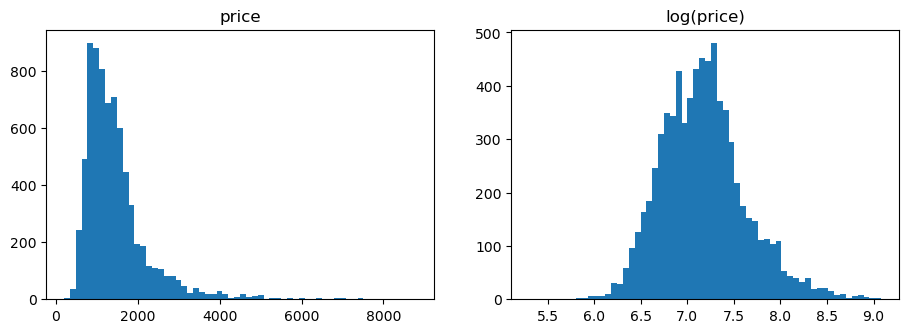

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train["price"], bins=60)
axes[0].set_title("price")
axes[1].hist(np.log(train["price"]), bins=60)
axes[1].set_title("log(price)")
plt.show()

**What we found**
- 7,398 rows, no missing values (imputers stay in the pipeline as a safety net in case test has blanks).
- `price` is right-skewed ($200 to $8,800, median ≈ $1,274). `log(price)` looks much more symmetric, so it's worth trying in Step 4.
- `category` is almost always `housing/rent/apartment` (only 3 other rows), so it carries almost no information. We keep it; one-hot handles it.
- `ID` is just a row number and is **not** used as a feature.

### 1.3 Features and target

In [8]:
TARGET = "price"
NUM_COLS = ["bathrooms", "bedrooms", "square_feet", "latitude", "longitude"]
CAT_COLS = ["category", "has_photo", "state"]

X = train[NUM_COLS + CAT_COLS]
y = train[TARGET]
X.shape, y.shape

((7398, 8), (7398,))

### 1.4 Preprocessing (ColumnTransformer)
Numbers: median imputer (+ StandardScaler for linear models). Words: most-frequent imputer + one-hot. Trees don't need scaling, so `scale` is a switch.

In [9]:
def make_preprocessor(scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    cat_steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_COLS),
        ("cat", Pipeline(cat_steps), CAT_COLS),
    ])

make_preprocessor(scale=True).fit_transform(X).shape

(7398, 61)

## Step 2: Validation strategy
5-fold cross-validation on the training file only, same folds and same metric (RMSE) for every model. Preprocessing lives inside the Pipeline, so it is re-fit on each training fold (no leakage).

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"

results = []   # one row per model, becomes the comparison table

def evaluate(name, model, scale=False):
    """5-fold CV of preprocessing + model. Records train RMSE and CV RMSE."""
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", model)])
    cv_out = cross_validate(pipe, X, y, cv=cv, scoring=SCORING,
                            return_train_score=True, n_jobs=-1)
    row = {
        "model": name,
        "train_rmse": -cv_out["train_score"].mean(),
        "cv_rmse_mean": -cv_out["test_score"].mean(),
        "cv_rmse_std": cv_out["test_score"].std(),
    }
    results = [r for r in globals()["results"] if r["model"] != name]
    results.append(row)
    globals()["results"] = results
    return pd.DataFrame(results).round(1)

Sanity check: a baseline that always guesses the mean price. Every real model should beat this.

In [11]:
evaluate("Baseline (mean)", DummyRegressor(strategy="mean"))

,model,train_rmse,cv_rmse_mean,cv_rmse_std
0,Baseline (mean),821.4,820.7,41.8


## Step 3: Four required models
*(next)*